# Pricing and stopping: mathematical foundations in computation

I connect conditional expectation, diffusion pricing, backward induction and regression to the repository's implementations. The example is a one-asset call with $S_0=K=100$, $r=0.05$, $q=0.10$, $\sigma=0.20$ and $T=3$, a one-dimensional specialisation of the published max-call benchmark. Its nine positive exercise dates are $t_j=j/3$, $j=1,\ldots,9$. The paper also includes time zero; its payoff is zero here, so that extra initial right does not increase the value of this non-negative claim.

All paths are simulated under a stipulated pricing model. There are no provider observations, market calibration inputs or historical replay results. This is a new illustrative experiment, not a reconstruction of the paper's fitted policies. I use the source pricing modules directly. Basic calculus, linear algebra and probability are assumed; numerical agreement is evidence about implementations, rather than an exact price certificate.

In [1]:
from pathlib import Path
from fractions import Fraction
from dataclasses import replace
import hashlib
import json
import shutil
import subprocess
import tempfile
import platform
import sys
import numpy as np
import matplotlib.pyplot as plt

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/qf_research/optimal_stopping/contracts.py").is_file())
sys.path.insert(0, str(ROOT / "src"))
from qf_research.optimal_stopping.contracts import Market, Option
from qf_research.optimal_stopping.analytical import black_scholes, black_scholes_greeks
from qf_research.optimal_stopping.tree import binomial_price
from qf_research.optimal_stopping.finite_difference import finite_difference_price
from qf_research.optimal_stopping.simulation import simulate_gbm, estimate_samples
from qf_research.optimal_stopping.least_squares import train_policy, evaluate_policy

MODULE_NAMES = ("contracts", "analytical", "tree", "finite_difference", "simulation", "least_squares")
source_hashes = {f"src/qf_research/optimal_stopping/{name}.py":
                 hashlib.sha256((ROOT/f"src/qf_research/optimal_stopping/{name}.py").read_bytes()).hexdigest()
                 for name in MODULE_NAMES}
EXPECTED_SOURCE_SHA256 = {'src/qf_research/optimal_stopping/analytical.py': '5fd072b2234e1d82ee0832225a8f83766845cc39b49f3162ba368e87ac67c198', 'src/qf_research/optimal_stopping/contracts.py': 'f00a256b820edc3371b0f315d676a00e1ef28fd9c144ccc88fd21cf21b22cf6a', 'src/qf_research/optimal_stopping/finite_difference.py': 'ddcd4bc9637de3777315485f567100b0526aa601b08fe7cf42c7e8d7072be1d3', 'src/qf_research/optimal_stopping/least_squares.py': '4373cbdadb00cd829cfc384eecdea867894576065ed4fb5c2e54f37e12e95be1', 'src/qf_research/optimal_stopping/simulation.py': '1161dfc31c51d79b26afb37a4d8e7b39c14153b7853d184c49c508616c7dc17a', 'src/qf_research/optimal_stopping/tree.py': 'd066fd36e4df8ad0fb8ff694212c72ea4e9c451c92e1b2c546cf617744879d6f', 'cpp/bermudan_tree.cpp': '6b9a07a51fe53fae50edf2966c46f997d69b73ca731fd6d5c7a76e67f4244d48'}
assert all(hashlib.sha256((ROOT/name).read_bytes()).hexdigest() == identity
           for name, identity in EXPECTED_SOURCE_SHA256.items())
assert all(Path(sys.modules[f"qf_research.optimal_stopping.{name}"].__file__).resolve()
           == (ROOT/f"src/qf_research/optimal_stopping/{name}.py").resolve() for name in MODULE_NAMES)
print(f"Python {platform.python_version()}; NumPy {np.__version__}")
print("Seven source identities checked; full hashes are retained in notebook metadata.")
cpp_evaluated = False


Matplotlib is building the font cache; this may take a moment.


Python 3.13.9; NumPy 2.3.5
Seven source identities checked; full hashes are retained in notebook metadata.


## 1. Conditional expectation and $L^2$ projection

Let $\Omega=\{0,1,2,3\}$ have probabilities $(1/8,3/8,1/4,1/4)$ and let $X=(-2,2,4,8)$. The information $\mathcal G$ distinguishes the blocks $A_0=\{0,1\}$ and $A_1=\{2,3\}$. A $\mathcal G$-measurable variable is constant on each block. Its conditional mean is
\[
C(\omega)=\frac{\sum_{i\in A_k}p_iX_i}{\sum_{i\in A_k}p_i},\qquad \omega\in A_k.
\]
It satisfies $\mathbb E[X\mathbf1_A]=\mathbb E[C\mathbf1_A]$ for every $A\in\mathcal G$. For integrable $X$ on a general probability space, this defines the Radon–Nikodym derivative of the finite signed measure $A\mapsto\mathbb E[X\mathbf1_A]$, restricted to $\mathcal G$, with respect to the probability measure.

For $X\in L^2$, the residual is orthogonal to every $Z\in L^2(\mathcal G)$. Expanding $X-Z=(X-C)+(C-Z)$ gives
\[
\mathbb E[(X-Z)^2]=\mathbb E[(X-C)^2]+\mathbb E[(C-Z)^2].
\]
Thus conditional expectation minimises mean-square prediction error with the available information. The following rational calculation checks the defining property and the projection identity exactly.

In [2]:
p = (Fraction(1, 8), Fraction(3, 8), Fraction(1, 4), Fraction(1, 4))
x = (-2, 2, 4, 8)
blocks = ((0, 1), (2, 3))
assert sum(p) == 1 and all(weight > 0 for weight in p)
c = [Fraction(0)] * 4
for block in blocks:
    mean = sum(p[i]*x[i] for i in block) / sum(p[i] for i in block)
    for i in block:
        c[i] = mean
    assert sum(p[i]*(x[i]-c[i]) for i in block) == 0
z = (Fraction(0), Fraction(0), Fraction(5), Fraction(5))
expectation = lambda values: sum(weight*value for weight, value in zip(p, values))
residual_risk = expectation([(x[i]-c[i])**2 for i in range(4)])
competitor_risk = expectation([(x[i]-z[i])**2 for i in range(4)])
projection_error = expectation([(c[i]-z[i])**2 for i in range(4)])
assert expectation([(x[i]-c[i])*z[i] for i in range(4)]) == 0
assert competitor_risk == residual_risk + projection_error
print("Conditional expectation:", tuple(str(value) for value in c))
print(f"Minimum squared risk {residual_risk}; competitor risk {competitor_risk}; excess {projection_error}.")

Conditional expectation: ('1', '1', '6', '6')
Minimum squared risk 7/2; competitor risk 9/2; excess 1.


### A finite stopping calculation

On four equiprobable paths, let $M_1=\xi_1$ and $M_2=\xi_1+\xi_2$, where the two independent increments take values $-1$ and $1$. Stop at the first date if $\xi_1=1$, and at the second date otherwise. This rule uses only current information. The identity $M_\tau=\xi_1+\mathbf1_{\{\tau\geq2\}}\xi_2$ expresses the stopped value through predictable indicators. Its mean is zero because each increment has conditional mean zero. Conditioning instead on the realised stopping date can give a nonzero mean. The paper's martingale assessment uses the first identity, conditional on the frozen fit, rather than conditioning on when exercise occurred.

In [3]:
from itertools import product
finite_paths = tuple(product((-1, 1), repeat=2))
weight = Fraction(1, len(finite_paths))
stop = lambda first: 1 if first == 1 else 2
stopped = lambda first, second: first if stop(first) == 1 else first+second
stopped_mean = sum(weight*stopped(first, second) for first, second in finite_paths)
predictable_mean = sum(weight*(first+int(stop(first) >= 2)*second)
                       for first, second in finite_paths)
assert stopped_mean == predictable_mean == 0
first_date_paths = [(first, second) for first, second in finite_paths if stop(first) == 1]
conditional_mean = sum(Fraction(stopped(first, second), len(first_date_paths))
                       for first, second in first_date_paths)
assert conditional_mean == 1
print(f"Exact stopped-martingale mean: {stopped_mean}.")
print(f"Mean conditional on stopping at the first date: {conditional_mean}.")

Exact stopped-martingale mean: 0.
Mean conditional on stopping at the first date: 1.


## 2. Itô's formula, pricing and sensitivities

Under $\mathbb Q$, $dS_t=(r-q)S_t\,dt+\sigma S_t\,dW_t$. Itô's formula applied to $\log S_t$ subtracts the quadratic-variation term $\sigma^2/2$, giving
\[
S_{t+h}=S_t\exp\{(r-q-\sigma^2/2)h+\sigma\sqrt h\,Z\},\qquad Z\sim N(0,1).
\]
Independent innovations give exact mathematical transitions at the selected dates. Floating-point normal sampling and exponentiation remain numerical computations. A discounted expectation under $\mathbb Q$ is a valuation, not a physical-return forecast.

Integrating the European terminal payoff gives the established Black–Scholes–Merton call formula
\[
C=S_0e^{-qT}\Phi(d_1)-Ke^{-rT}\Phi(d_2),\quad
 d_1=\frac{\log(S_0/K)+(r-q+\sigma^2/2)T}{\sigma\sqrt T},\quad d_2=d_1-\sigma\sqrt T.
\]
I check implemented Greeks against centred finite differences. Smooth first differences have leading $O(h^2)$ truncation error; second differences can amplify rounding error at very small steps. Vega and rho are per unit change in volatility and rate. Theta is per calendar year, hence the negative maturity derivative.

In [4]:
market = Market(spot=100.0, rate=0.05, volatility=0.20, dividend=0.10)
option = Option(strike=100.0, maturity=3.0, kind="call")
dates = tuple(j/3 for j in range(1, 10))
european_value = black_scholes(market, option)
greeks = black_scholes_greeks(market, option)
hs, hv, hr, ht = 0.05, 1e-4, 1e-5, 1e-4
spot_plus = black_scholes(replace(market, spot=market.spot+hs), option)
spot_minus = black_scholes(replace(market, spot=market.spot-hs), option)
differences = {
    "delta": (spot_plus-spot_minus)/(2*hs),
    "gamma": (spot_plus-2*european_value+spot_minus)/hs**2,
    "vega": (black_scholes(replace(market, volatility=market.volatility+hv), option)
             - black_scholes(replace(market, volatility=market.volatility-hv), option))/(2*hv),
    "rho": (black_scholes(replace(market, rate=market.rate+hr), option)
            - black_scholes(replace(market, rate=market.rate-hr), option))/(2*hr),
    "theta": -(black_scholes(market, replace(option, maturity=option.maturity+ht))
               - black_scholes(market, replace(option, maturity=option.maturity-ht)))/(2*ht),
}
print(f"European call value: {european_value:.8f}")
print(f"{'Sensitivity':<12} {'Analytical':>12} {'Difference':>12} {'Absolute discrepancy':>22}")
for name, computed in differences.items():
    analytical = getattr(greeks, name)
    assert np.isfinite(computed) and np.isfinite(analytical)
    print(f"{name:<12} {analytical:12.8f} {computed:12.8f} {abs(computed-analytical):22.3g}")

European call value: 6.02078880
Sensitivity    Analytical   Difference   Absolute discrepancy
delta          0.29447975   0.29447974               8.59e-09
gamma          0.00824847   0.00824847               1.38e-09
vega          49.49084966  49.49084849               1.17e-06
rho           70.28155900  70.28155900               1.23e-09
theta          0.12374321   0.12374321               2.87e-10


## 3. Same-calendar tree and PDE references

The generator is $\mathcal L f=(r-q)s f_s+\sigma^2s^2f_{ss}/2$. Between rights, $V_t+\mathcal L V-rV=0$; at a right, $V$ is replaced by $\max\{(s-K)^+,V_{\rm continuation}\}$. The exercise projection implements the same Bellman decision as a risk-neutral binomial tree. Refining the numerical grid approximates a fixed contract; adding exercise dates changes that contract.

I use the source CRR and finite-difference solvers. The latter uses a tridiagonal operator, adjusts drift where needed for non-negative off-diagonal generator entries, and applies implicit smoothing after exercise projections. These choices do not remove grid, interpolation or boundary errors. Time and space are refined jointly. The expanded-domain comparison keeps the finest spatial spacing fixed; it remains a numerical reference, not an exact diffusion price or a certified bound.

In [5]:
time_steps = (360, 720, 1440)
space_steps = (400, 800, 1600)
grid_records = []
for nt, ns in zip(time_steps, space_steps):
    tree = binomial_price(market, option, nt, dates=dates)
    pde = finite_difference_price(market, option, ns, nt, s_max=400.0, dates=dates)
    assert np.isfinite(tree.value) and np.isfinite(pde.value)
    assert np.isclose(option.maturity/nt*(nt//9), 1/3)
    grid_records.append((nt, ns, tree.value, pde.value, pde.upwind_nodes))
expanded = finite_difference_price(market, option, 2400, 1440, s_max=600.0, dates=dates)
european_pde = finite_difference_price(market, option, 1600, 1440, s_max=400.0, dates=None)
reference = expanded.value
print(f"{'Time steps':>10} {'Space steps':>12} {'CRR':>12} {'PDE':>12} {'Absolute difference':>20}")
for nt, ns, tv, pv, upwind in grid_records:
    print(f"{nt:10d} {ns:12d} {tv:12.8f} {pv:12.8f} {abs(tv-pv):20.6g}")
print(f"Expanded-domain PDE reference: {reference:.8f}")
print(f"Domain-change discrepancy at spatial spacing 0.25: {abs(reference-grid_records[-1][3]):.3g}")
print(f"European PDE versus analytical value: {abs(european_pde.value-european_value):.3g}")
print("Upwind-adjusted nodes by grid:", [row[-1] for row in grid_records])
assert reference >= european_value

Time steps  Space steps          CRR          PDE  Absolute difference
       360          400   7.96443191   7.96235976           0.00207215
       720          800   7.96422971   7.96345563          0.000774072
      1440         1600   7.96413333   7.96371138          0.000421948
Expanded-domain PDE reference: 7.96371138
Domain-change discrepancy at spatial spacing 0.25: 0
European PDE versus analytical value: 7.51e-05
Upwind-adjusted nodes by grid: [1, 1, 1]


The figure tests whether two independent discretisations approach a similar value as resolution increases. Vertical differences are numerical discrepancies, not confidence intervals. Joint refinement does not identify a separate temporal or spatial convergence order; the domain check diagnoses a different source of error.

The exercise value exceeds the European value by about 1.943 price units in these grids. Dividend yield gives early exercise an economic role: delaying a call forfeits dividends while postponing payment of the strike and preserving option time value. The optimal rule balances these effects, rather than exercising solely because the option is in the money.

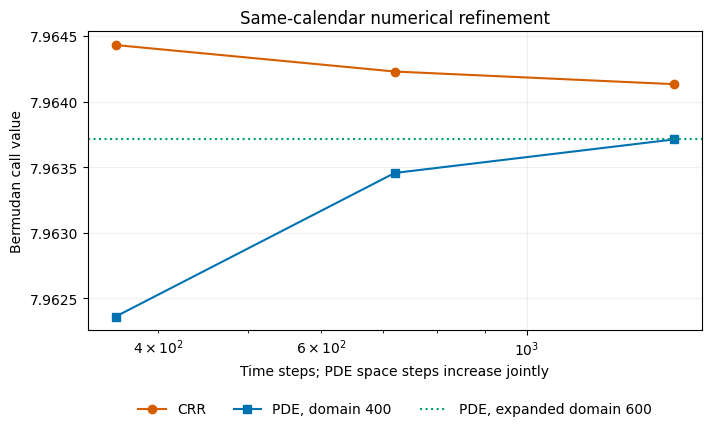

In [6]:
fig, ax = plt.subplots(figsize=(7.0, 4.2), constrained_layout=True)
ax.plot(time_steps, [row[2] for row in grid_records], "o-", color="#D55E00", label="CRR")
ax.plot(time_steps, [row[3] for row in grid_records], "s-", color="#0072B2", label="PDE, domain 400")
ax.axhline(reference, color="#009E73", linestyle=":", label="PDE, expanded domain 600")
ax.set(xscale="log", xlabel="Time steps; PDE space steps increase jointly",
       ylabel="Bermudan call value", title="Same-calendar numerical refinement")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.20), ncol=3, frameon=False)
ax.grid(alpha=0.2)
plt.show()
plt.close(fig)

## 4. A native C++ rollback

I implement the same CRR recursion independently in [C++17](../cpp/bermudan_tree.cpp). For $h=T/N$, the up/down multipliers are $u=e^{\sigma\sqrt h}$ and $d=1/u$, with risk-neutral probability $p=\{e^{(r-q)h}-d\}/(u-d)$. Discounted continuation is $e^{-rh}\{pV_{\rm up}+(1-p)V_{\rm down}\}$. Exercise takes the maximum with the payoff only at the nine specified positive rights.

A single owning vector supports in-place backward induction, with $O(N)$ storage and $O(N^2)$ work. Checked inputs and arithmetic reject unsupported calendars, probabilities and representational failures. In the zero-volatility branch, optimisation is over deterministic discounted rewards. These implementation choices are visible in the source; cross-language agreement does not certify diffusion accuracy. The cell compiles and compares the three reference grids when a C++17 compiler is available. The separate [verification driver](../scripts/verify_bermudan_tree.py) also checks independent finite-tree and deterministic references, invalid inputs and limiting cases.

In [7]:
compiler = next((shutil.which(name) for name in ("clang++", "g++", "c++")
                 if shutil.which(name)), None)
if compiler is None:
    print("Native C++ comparison not executed: a C++17 compiler is required.")
else:
    flags = ["-std=c++17", "-O2", "-fno-fast-math", "-ffp-contract=off"]
    with tempfile.TemporaryDirectory(prefix="bermudan-reference-") as temporary:
        executable = Path(temporary)/"bermudan_tree"
        build = subprocess.run([compiler, *flags, str(ROOT/"cpp/bermudan_tree.cpp"),
                                "-o", str(executable)], capture_output=True, text=True,
                               timeout=60)
        if build.returncode:
            raise RuntimeError("The native pricing source did not compile successfully.")
        native_records = []
        for nt, ns, python_value, pde_value, upwind in grid_records:
            arguments = [market.spot, option.strike, option.maturity, market.rate,
                         market.dividend, market.volatility, option.kind, nt, len(dates)]
            run = subprocess.run([str(executable), *map(str, arguments)],
                                 capture_output=True, text=True, timeout=30)
            if run.returncode:
                raise RuntimeError("The native calculation rejected the reference contract.")
            value = json.loads(run.stdout)
            assert value["ok"] and value["author"] == "Amanjeet Singh"
            assert not value["time_zero_exercise"]
            difference = abs(value["value"]-python_value)
            assert difference <= 2e-10+2e-11*abs(python_value)
            native_records.append((nt, value["value"], difference))
        cpp_evaluated = True
    print("C++17 compiler:", Path(compiler).name)
    print(f"{'Time steps':>10} {'Native CRR':>14} {'Python discrepancy':>20}")
    for nt, value, difference in native_records:
        print(f"{nt:10d} {value:14.8f} {difference:20.3g}")

C++17 compiler: clang++
Time steps     Native CRR   Python discrepancy
       360     7.96443191                    0
       720     7.96422971                    0
      1440     7.96413333                    0


## 5. Regression, rank and an independent policy evaluation

For discounted reward $H_j=e^{-rt_j}(S_j-K)^+$, the Snell recursion is $Y_J=H_J$ and $Y_j=\max\{H_j,\mathbb E[Y_{j+1}\mid\mathcal F_j]\}$. Longstaff–Schwartz backward regression approximates continuation with a finite-basis fit. Population projection, basis approximation and the sample least-squares solve are distinct operations.

I request degree two, matching the paper's baseline span in one dimension. This source implementation centres and scales the in-the-money spot sample before fitting $1,x,x^2$ with SVD least squares. Non-degenerate affine normalisation preserves the polynomial span while changing conditioning. The implementation reduces degree if rank or its condition-number safeguard fails and continues without a usable fit. These are its own numerical choices, not a replay of the paper's multivariate policies.

Coefficients are frozen before forward evaluation on an independent stream. The rule uses current spot and its saved regression; ties continue. Conditional on this fit, independent discounted payoffs estimate the implemented policy value. Training uncertainty and the shortfall relative to optimal exercise remain separate questions.

In [8]:
N_TRAIN, N_EVALUATION, DEGREE = 32768, 65536, 2
root_seed = np.random.SeedSequence(2026101117)
training_seed, evaluation_seed = root_seed.spawn(2)
policy = train_policy(market, option, dates, N_TRAIN, DEGREE,
                      np.random.default_rng(training_seed))
evaluation_paths = simulate_gbm(market, np.asarray(policy.times), N_EVALUATION,
                                 np.random.default_rng(evaluation_seed))
result = evaluate_policy(policy, evaluation_paths)
assert policy.training_paths == N_TRAIN and policy.requested_degree == DEGREE
assert result.raw.observations == result.european_control.observations == N_EVALUATION
assert np.array_equal(np.asarray(policy.times)[1:], np.asarray(dates))
assert np.all(np.isfinite(evaluation_paths)) and np.all(evaluation_paths > 0)
print(f"Training paths: {N_TRAIN:,}; independent evaluation paths: {N_EVALUATION:,}.")
print(f"Total new paths: {N_TRAIN+N_EVALUATION:,}; Gaussian innovations: {9*(N_TRAIN+N_EVALUATION):,}.")
print(f"{'Right':>5} {'ITM rows':>10} {'Rank':>7} {'Basis size':>11} {'Condition number':>18}")
for j, fit in enumerate(policy.regressions[1:-1], start=1):
    if fit is None:
        print(f"{j:5d} {'continue':>10}")
    else:
        assert fit.rank == len(fit.coefficients) and np.isfinite(fit.condition_number)
        print(f"{j:5d} {fit.observations:10d} {fit.rank:7d} {len(fit.coefficients):11d} {fit.condition_number:18.4g}")

Training paths: 32,768; independent evaluation paths: 65,536.
Total new paths: 98,304; Gaussian innovations: 884,736.
Right   ITM rows    Rank  Basis size   Condition number
    1      13775       3           3              3.701
    2      12717       3           3              3.791
    3      11959       3           3              3.966
    4      11307       3           3              4.115
    5      10754       3           3              4.233
    6      10194       3           3              4.287
    7       9774       3           3              4.365
    8       9337       3           3              4.395


## 6. Sampling uncertainty and the European control

Write $Y=e^{-r\tau}(S_\tau-K)^+$ and $Z=e^{-rT}(S_T-K)^+$. Since $\mathbb E[Z]=C$, the fixed-coefficient control $Y-(Z-C)$ has the same mean as $Y$. No coefficient is fitted on evaluation outcomes. Its variance is
\[
\operatorname{Var}(Y-Z)=\operatorname{Var}(Y)+\operatorname{Var}(Z)-2\operatorname{Cov}(Y,Z).
\]
Variance falls precisely when $2\operatorname{Cov}(Y,Z)>\operatorname{Var}(Z)$, so the control need not help every policy. I report its observed variance ratio.

The standard error is the sample standard deviation divided by $\sqrt n$. The $n^{-1/2}$ rate does not imply dimension-independent runtime: variance, fitting difficulty and work per path can change with dimension. The approximate 95 per cent Student intervals describe evaluation noise conditional on one fitted policy. They have no established exact coverage here and exclude training, discretisation and model error. A sample policy estimate is not a deterministic lower bound.

In [9]:
cash = result.discounted_payoffs
terminal = np.exp(-market.rate*option.maturity)*option.payoff(evaluation_paths[:, -1])
controlled = cash-terminal+european_value
terminal_estimate = estimate_samples(terminal)
raw_variance = float(np.var(cash, ddof=1))
terminal_variance = float(np.var(terminal, ddof=1))
covariance = float(np.cov(cash, terminal, ddof=1)[0, 1])
controlled_variance = float(np.var(controlled, ddof=1))
assert np.isclose(controlled_variance, raw_variance+terminal_variance-2*covariance,
                  rtol=1e-12, atol=1e-10)
assert np.isclose(result.european_control.standard_error**2*N_EVALUATION,
                  controlled_variance, rtol=1e-12)
print(f"{'Estimate':<23} {'Value':>11} {'SE':>11} {'Approximate 95% interval':>29}")
for label, estimate in (("European, same paths", terminal_estimate),
                        ("Frozen policy, raw", result.raw),
                        ("Frozen policy, control", result.european_control)):
    print(f"{label:<23} {estimate.value:11.6f} {estimate.standard_error:11.6f} "
          f"[{estimate.lower:.6f}, {estimate.upper:.6f}]")
print(f"Observed control/raw variance ratio: {controlled_variance/raw_variance:.4f}")
print(f"European sampling discrepancy: {terminal_estimate.value-european_value:+.6f}")
print(f"Numerical reference minus controlled policy estimate: {reference-result.european_control.value:+.6f}")
print(f"Early exercise fraction: {np.mean(result.stopping_indices < 9):.4f}")
assert np.all((result.stopping_indices >= 1) & (result.stopping_indices <= 9))
assert all(hashlib.sha256((ROOT/name).read_bytes()).hexdigest() == identity
           for name, identity in EXPECTED_SOURCE_SHA256.items())

Estimate                      Value          SE      Approximate 95% interval
European, same paths       5.914470    0.057120 [5.802516, 6.026425]
Frozen policy, raw         7.881826    0.046668 [7.790357, 7.973295]
Frozen policy, control     7.988144    0.047682 [7.894687, 8.081601]
Observed control/raw variance ratio: 1.0439
European sampling discrepancy: -0.106318
Numerical reference minus controlled policy estimate: -0.024433
Early exercise fraction: 0.2965


In this retained run the coefficient-one European control increases sample variance slightly (control/raw ratio about 1.044). The control preserves the population mean, but its coefficient was not optimised for variance. I retain this outcome because it illustrates the difference between a correct identity and a useful numerical method.

The reference-minus-estimate difference combines numerical reference error, conditional sampling error and any policy shortfall. Its sign in one run does not certify optimality or establish arbitrage. The European calculation reuses the evaluation sample and adds no independent paths. One fit and one evaluation cannot establish a performance ranking, coverage result or retraining variability.

## 7. Interpretive exercise

If the controlled estimate exceeds the finest PDE reference by less than one estimated standard error, has the policy beaten the optimal stopping value? Explain sampling uncertainty, grid/domain error and the inequality between an admissible policy's expected reward and the true optimum. Would adding intermediate exercise dates cleanly test convergence for this contract?

Answer scaffold: compare expectations with sample estimates, identify numerical approximations, and distinguish solver refinement from changing the exercise set. Record an explanation before opening the answer.

<details>
<summary>Interpretation</summary>

The apparent excess can arise from sampling noise, numerical reference error, or both. An admissible policy's expected reward cannot exceed the optimum for the same model and calendar. A sample mean and an approximate PDE price do not enforce that inequality pointwise. The standard error concerns conditional evaluation noise; grid and domain tests concern other errors. Adding rights expands the stopping set and can increase contract value. I would retain the calendar, investigate numerical refinement, and add independent evaluation only if sampling uncertainty prevents the intended comparison.

</details>

## 8. Sources and scope

The established methods retain their attribution. The rational example and explanatory derivations are written for this tutorial and make no claim of theoretical priority. Source identities are retained in metadata and rechecked after execution. The notebook metadata records the source identities and simulation design. The reproduction guide explains execution from a fresh kernel.

Black, F. and Scholes, M. (1973), [The Pricing of Options and Corporate Liabilities](https://www.journals.uchicago.edu/doi/10.1086/260062), *Journal of Political Economy*, 81, 637–654. Merton, R. C. (1973), [Theory of Rational Option Pricing](https://www.maths.tcd.ie/~dmcgowan/Merton.pdf), *Bell Journal of Economics and Management Science*, 4, 141–183.

Cox, J. C., Ross, S. A. and Rubinstein, M. (1979), [Option pricing: A simplified approach](https://www.sciencedirect.com/science/article/pii/0304405X79900151), *Journal of Financial Economics*, 7, 229–263. Longstaff, F. A. and Schwartz, E. S. (2001), [Valuing American Options by Simulation: A Simple Least-Squares Approach](https://doi.org/10.1093/rfs/14.1.113), *Review of Financial Studies*, 14, 113–147.

Andersen, L. and Broadie, M. (2004), [Primal-Dual Simulation Algorithm for Pricing Multidimensional American Options](https://doi.org/10.1287/mnsc.1040.0258), *Management Science*, 50, 1222–1234, supplies the benchmark context. For probability foundations, see Jacod, J. and Protter, P. (2004), *Probability Essentials*, second edition, Springer. The repository source register gives further numerical-method references.